# Task 4: Game title detection

รายงาน EDA จากภาพในเครื่อง วันที่ 2 พฤศจิกายน 2026 ไม่มีการฝึกโมเดล

## 1. Task Overview

ระบุชื่อเกมจาก screenshot เพื่อจัดหมวดภาพและคำร้องของผู้เล่น

Target คือ `class` จำนวน 5 เกม ไม่พบ metric ทางการ แนะนำ macro F1 และ accuracy เป็น local proxy

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / 'sample_submission.csv').exists())
sys.path.insert(0, str(ROOT))
from shared.eda_utils import (
    TASKS, load_task, quality_table, outlier_table, bounds_table,
    association, strongest_pairs, period_changes, image_inventory, setup_plot,
)
setup_plot()

train, test, target, base = load_task(ROOT, 4)

## 2. Dataset Overview

| ค่าใน CSV | รหัสคำตอบ | เกมตาม data card |
|---|---|---|
| 7-11k | 0 | 7-11 Knights |
| fiveN | 1 | FiveN |
| freefried | 2 | Free Fried |
| pube | 3 | PUBE |
| roblock | 4 | Roblock |

ภาพ JPEG คาดหวังขนาด 230×120, RGB 8-bit; id เชื่อมกับ `{split}/{id}.jpg` ภายในโฟลเดอร์ข้อมูลภาพจริง

In [2]:
display(pd.DataFrame({'split': ['train', 'test'], 'rows': [len(train), len(test)],
                      'labels': [train['class'].notna().sum(), test['class'].notna().sum()]}))
display(train.drop(columns='id').head())
display(train.dtypes.astype(str).to_frame('dtype'))

,split,rows,labels
0,train,31546,31546
1,test,25889,0


,class
0,7-11k
1,roblock
2,7-11k
3,freefried
4,7-11k


,dtype
id,str
class,str


**Findings & Interpretation**

**Findings:** Train CSV มี 31,546 แถว และ test 25,889 แถว; test class ไม่มีค่าทุกแถว

**Interpretation:** จำนวนแถวใน manifest ไม่รับประกันว่ามีไฟล์ภาพครบ

**ML Implications:** ตรวจ path จริงก่อนสร้าง training set

**Recommended Action:** ตรวจการมีอยู่ ความอ่านได้ ขนาด และ mode ของไฟล์ทั้งหมด

## 3. Data Quality Analysis

In [3]:
train_inventory = image_inventory(base, train, 'train')
test_inventory = image_inventory(base, test, 'test')
artifacts = ROOT / 'artifacts'
artifacts.mkdir(exist_ok=True)
train_inventory.to_csv(artifacts / 'image_train_inventory.csv', index=False)
test_inventory.to_csv(artifacts / 'image_test_inventory.csv', index=False)
quality = pd.DataFrame([
    {'split': split, 'manifest_rows': len(inventory), 'exists': inventory.exists.sum(),
     'readable': inventory.readable.sum(),
     'corrupt': (inventory.exists & ~inventory.readable).sum()}
    for split, inventory in [('train', train_inventory), ('test', test_inventory)]
])
display(quality)
print('Duplicate train IDs:', train.id.duplicated().sum())
print('Duplicate test IDs:', test.id.duplicated().sum())

Duplicate train IDs: 0
Duplicate test IDs: 0


,split,manifest_rows,exists,readable,corrupt
0,train,31546,2811,2811,0
1,test,25889,25889,25889,0


**Findings & Interpretation**

**Findings:** Train อ่านได้ 2,811/31,546 ภาพ (8.91%); ขาด 28,735 ภาพ; test อ่านได้ 25,889/25,889; ไฟล์ที่มีอยู่แต่อ่านไม่ได้ 0

**Interpretation:** ข้อมูลฝึกภาพมีข้อจำกัดรุนแรง แต่ข้อมูล test ต้องทำนายครบทุกแถว

**ML Implications:** ใช้เฉพาะ readable train; ห้ามเติมภาพว่างแทนภาพฝึกที่ขาดเพราะจะสร้างสัญญาณเทียม

**Recommended Action:** กู้ไฟล์ train ที่ขาดจากแหล่งข้อมูลเดิมในรอบถัดไป

## 4. Statistical Analysis

,available,manifest,available_pct
class,,,
7-11k,1116,12429,8.9790
fiveN,409,4407,9.2807
freefried,457,5596,8.1665
pube,539,5926,9.0955
roblock,290,3188,9.0966


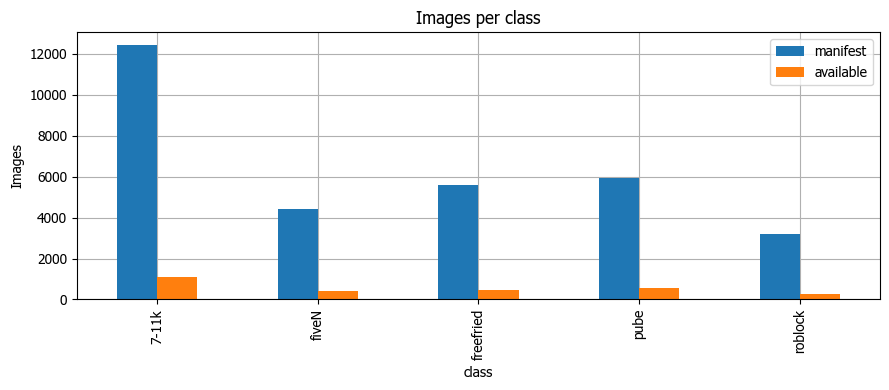

,,,,count
split,width,height,mode,
test,230.0000,120.0000,RGB,25889
train,230.0000,120.0000,RGB,2811


In [4]:
availability = train.merge(train_inventory, on='id', validate='one_to_one')
counts = availability.groupby('class').readable.agg(['sum', 'count'])
counts.columns = ['available', 'manifest']
counts['available_pct'] = counts.available / counts.manifest * 100
display(counts)
counts[['manifest', 'available']].plot.bar(title='Images per class', ylabel='Images')
plt.tight_layout()
plt.show()
display(pd.concat([train_inventory.assign(split='train'), test_inventory.assign(split='test')])
        .query('readable').groupby(['split', 'width', 'height', 'mode']).size().to_frame('count'))

**Findings & Interpretation**

**Findings:** ภาพ train ที่อ่านได้ต่อคลาสคือ {'7-11k': 1116, 'fiveN': 409, 'freefried': 457, 'pube': 539, 'roblock': 290}; อัตราภาพที่มีต่อคลาสอยู่ที่ 8.17% ถึง 9.28%

**Interpretation:** แต่ละคลาสมีภาพขาดมากและจำนวนตัวอย่างไม่เท่ากัน แม้อัตราภาพที่เหลือใกล้เคียงกัน ก็ยังยืนยันไม่ได้ว่า missing เป็นแบบสุ่ม

**ML Implications:** ใช้ stratified split และ macro F1; รายงานคะแนนบน available subset อย่างชัดเจน

**Recommended Action:** ตรวจภาพตัวอย่างและความซ้ำก่อนแบ่ง validation

## 5. Feature Relationships

In [5]:
train_hashes = train_inventory.loc[train_inventory.readable, 'sha256']
test_hashes = test_inventory.loc[test_inventory.readable, 'sha256']
print('Repeated train file hashes:', train_hashes.duplicated().sum())
print('Train/test exact file hash intersection:', len(set(train_hashes) & set(test_hashes)))
print('Train/test ID intersection:', len(set(train.id) & set(test.id)))
readable = availability.query('readable')
conflicts = readable.groupby('sha256')['class'].nunique()
print('Hashes assigned multiple labels:', conflicts.gt(1).sum())

Repeated train file hashes: 0
Train/test exact file hash intersection: 0
Train/test ID intersection: 0
Hashes assigned multiple labels: 0


**Findings & Interpretation**

**Findings:** พบ repeated SHA256 ใน train 0 แถว และ hash ตรงกันระหว่าง train/test 0 ค่า

**Interpretation:** การตรวจนี้ครอบคลุม exact file duplicates แต่ไม่จับภาพที่ถูก re-encode/crop หรือเฟรมใกล้กัน

**ML Implications:** random validation อาจยังมี near duplicate leakage ถึงแม้ exact hash จะไม่ตรงกัน

**Recommended Action:** ตรวจ perceptual hash หรือ group ตามวิดีโอต้นทางในรอบถัดไป

## 6. Task-Specific EDA

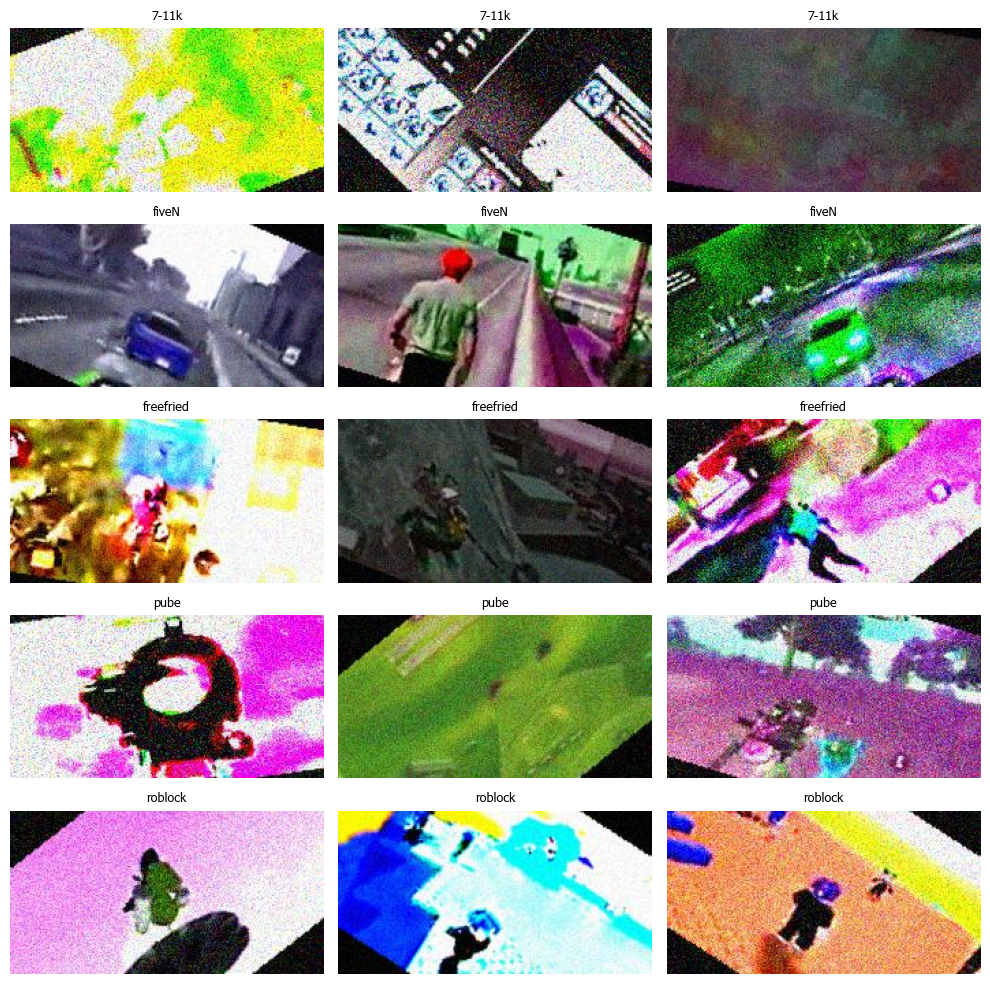

,red,green,blue
class,,,
7-11k,122.4946,121.8766,120.9819
fiveN,107.4066,107.2312,105.2815
freefried,105.6298,108.9179,106.5350
pube,107.6956,109.7053,109.2960
roblock,119.7295,115.7913,116.6587


In [6]:
fig, axes = plt.subplots(5, 3, figsize=(10, 10))
for row, label in enumerate(sorted(readable['class'].unique())):
    examples = readable.loc[readable['class'].eq(label)].sample(3, random_state=42)
    for axis, image_id in zip(axes[row], examples.id):
        with Image.open(base / 'train' / f'{image_id}.jpg') as image:
            axis.imshow(image)
        axis.set_title(label, fontsize=9)
        axis.axis('off')
plt.tight_layout()
plt.show()
colors = []
for image_id, label in zip(readable.id, readable['class']):
    with Image.open(base / 'train' / f'{image_id}.jpg') as image:
        rgb = np.asarray(image.convert('RGB').resize((24, 12)), dtype=float)
    colors.append({'class': label, 'red': rgb[:, :, 0].mean(),
                   'green': rgb[:, :, 1].mean(), 'blue': rgb[:, :, 2].mean()})
color_summary = pd.DataFrame(colors).groupby('class').mean()
display(color_summary)

**Findings & Interpretation**

**Findings:** ค่า mean RGB ระดับคลาสต่างกันสูงสุดระหว่างคลาส: R=16.86, G=14.65, B=15.70 บนสเกล 0–255; ภาพตัวอย่างสุ่มคลาสละ 3 ภาพ พบภาพเอียง สี/ความสว่างต่างกันมาก และ noise ที่มองเห็นได้ในหลายภาพตัวอย่าง

**Interpretation:** สีและองค์ประกอบภาพอาจให้สัญญาณเบื้องต้น แต่ค่าเฉลี่ยสีไม่ได้ยืนยันว่าจำแนกเกมได้ดี ยังไม่ทราบว่าลักษณะภาพเกิดจาก augmentation หรือภาพต้นฉบับ

**ML Implications:** ใช้ resized pixels/color histogram เป็น baseline ราคาถูก และตัดสินจาก validation ความไวต่อการหมุนและเปลี่ยนสีเป็นข้อจำกัดที่ควรตรวจต่อ

**Recommended Action:** เก็บภาพต้นฉบับไว้สำหรับ transfer learning เมื่อข้อมูลครบ

## 7. EDA Findings & Insights

- ภาพ train ใช้ได้ 2,811 ภาพ จาก manifest 31,546 แถว
- Test อ่านได้ 25,889 ภาพ
- Exact train/test file hash overlap 0 ค่า แต่ยังไม่ตรวจ near duplicates
- ความขาดของ train เป็นข้อจำกัดหลักของคะแนนและความเป็นตัวแทนของ validation

## 8. Preprocessing Recommendations

- กรอง readable train ก่อน split และคงลำดับ test ตาม CSV
- แปลง RGB, resize คงที่ และหาร pixel ด้วย 255; color histogram ใช้สัดส่วนในแต่ละ bin
- ใช้ mapping ตามตาราง data card ไม่ใช้ alphabetical label encoding
- ยังไม่ใช้ augmentation เพื่อให้ baseline ตรวจสอบง่าย; ไม่แทนภาพหายด้วยภาพว่าง

## 9. Baseline Model Recommendations

เทียบ ExtraTrees กับ SVM หลัง StandardScaler จาก pixel 24×12 และ RGB histogram บน CPU แบ่ง readable subset แบบ stratified 80/20 seed 42 ตรวจ macro F1, accuracy และ confusion matrix ความท้าทายคือข้อมูลฝึกขาดและ screenshot ใกล้กันอาจทำให้ validation สูงเกินจริง การฝึกอยู่ใน `02_baseline.ipynb`

## 10. Final EDA Summary

ยืนยันว่าภาพฝึกอ่านได้ 2,811 ภาพ โดยมีครบ 5 คลาส แต่ขาด 28,735 ภาพ ขั้นถัดไปคือสร้าง baseline จาก subset นี้และกู้ภาพที่ขาด ยังไม่ทราบเหตุที่ไฟล์ขาด แหล่งวิดีโอของภาพ และ metric ทางการ ไม่ควรตีความคะแนนบน subset ว่าแทนข้อมูลทั้งหมดได้